# 13 · Idea D — Curve Momentum

**状态：** documented negative/mixed。full-sample gross 很弱，all-in net 为负；test gross 也为负。

本 notebook 只负责一个 idea。PnL、持仓和 overall Sharpe 都来自 v2 正式口径；
历史 v1 内容不在这里重复，见 `docs/HANDOFF.md` 和 `docs/notebook_history.md`。


## 1. 约定 / Conventions

- 正式结果使用 v2 holdings-based simulator（D-019）。
- 口径：`d=5`、`k=5`、`min_adv=100`、USD 10m capital、equal-notional、
  三层成本（half-spread / fees / impact），见 D-018。
- PnL 曲线：`F.nav_by_cost_layer`，gross 加上三层成本，阴影是 2016 年起的
  post-hoc test sample。
- Overall Sharpe：full sample 1986–2026 的 **all-in net** 日收益，rf=0，
  252 天年化；每个 notebook 只报这一个 Sharpe。
- 持仓热力图：方向取最近到期腿（蓝=多，橙=空，白=空仓），大小是该品种的
  gross notional / capital；下图是组合 gross exposure 和年化换手。


## 2. 环境与数据 / Setup


In [1]:
import sys
import logging
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config, figures as F, plotstyle as ps, report, v2_rerun

logging.getLogger("fontTools").setLevel(logging.ERROR)
ps.use()
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
OUT = config.OUTPUT_DIR / "v2_rerun"
OUT.mkdir(parents=True, exist_ok=True)
ROOT_ORDER = (
    rank[["root", "sector"]]
    .drop_duplicates()
    .sort_values(["sector", "root"])["root"]
    .tolist()
)
rank.shape


(1013664, 23)

## 3. 运行 / Run


In [2]:
item = v2_rerun.run_strategy("d", rank)
v2_rerun.save_strategy(item, OUT)
res = item["result"]
print("saved:", OUT / "d_performance.csv", OUT / "d_root.csv")


saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/output/v2_rerun/d_performance.csv /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/output/v2_rerun/d_root.csv


## 4. Full-sample 总览 / Headline


In [3]:
full = item["performance"].xs("full", level="period").set_index("layer")
display(
    full[["ann_ret_pct", "ann_vol_pct", "max_dd_pct", "turnover_x"]]
    .round(3)
    .rename(columns={
        "ann_ret_pct": "Ann. ret (%)",
        "ann_vol_pct": "Ann. vol (%)",
        "max_dd_pct": "Max DD (%)",
        "turnover_x": "Turnover (x/yr)",
    })
)
print(f"Overall Sharpe (full sample, all-in net): {report.overall_sharpe(res):+.3f}")


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,0.219,0.881,-5.510,22.078
- half-spread,-0.074,0.883,-7.338,22.078
- fees,-0.202,0.884,-11.375,22.078
- impact (all),-1.418,0.931,-60.255,22.078


Overall Sharpe (full sample, all-in net): -1.523


## 5. PnL 曲线 / Cumulative PnL


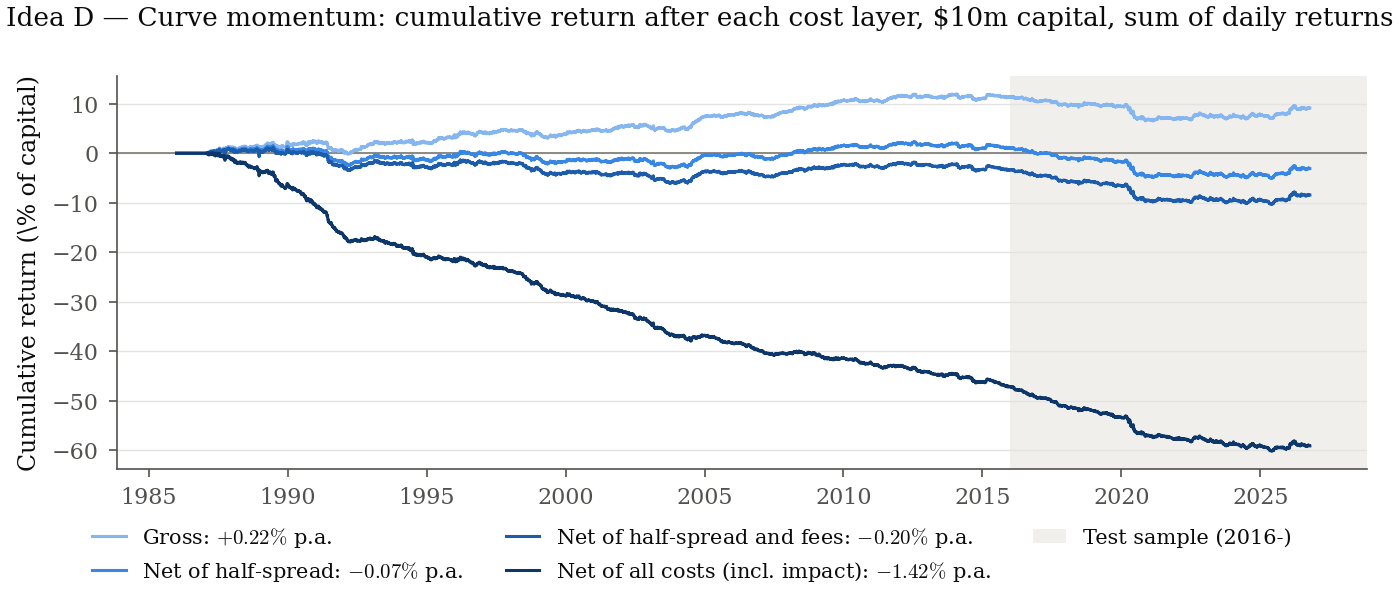

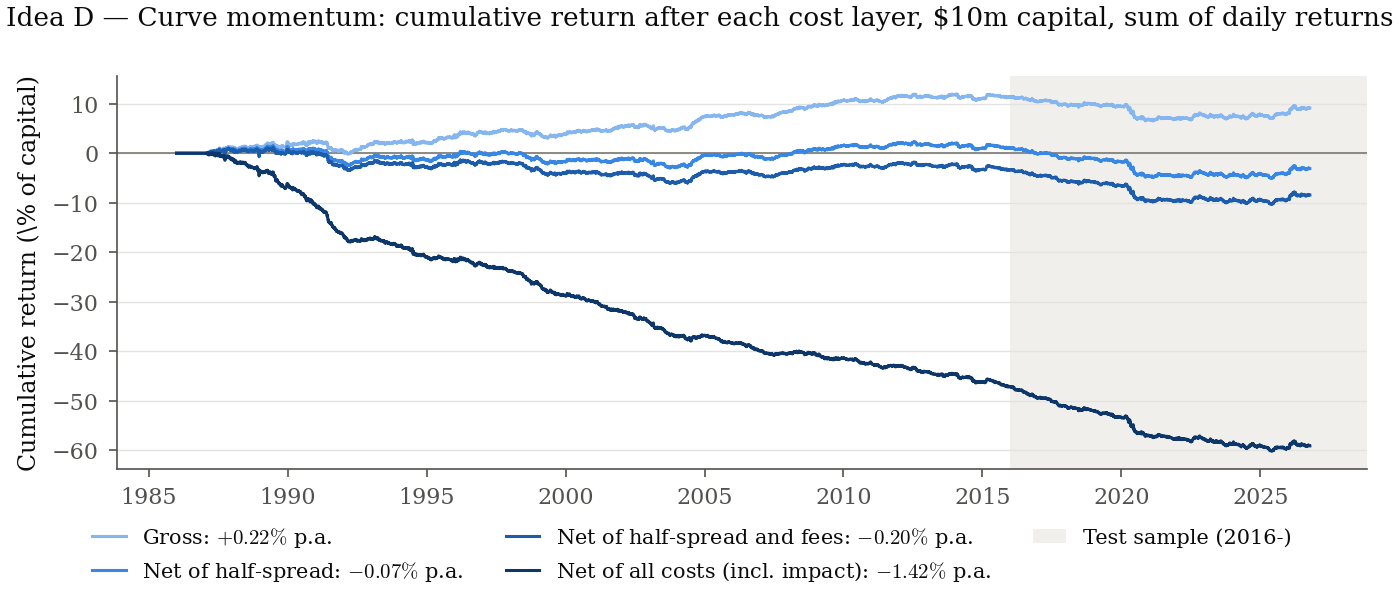

In [4]:
fig = F.nav_by_cost_layer(res, "Idea D — Curve momentum")
ps.save(fig, "idea_d_pnl")
display(fig)


## 6. 持仓变化 / Positions


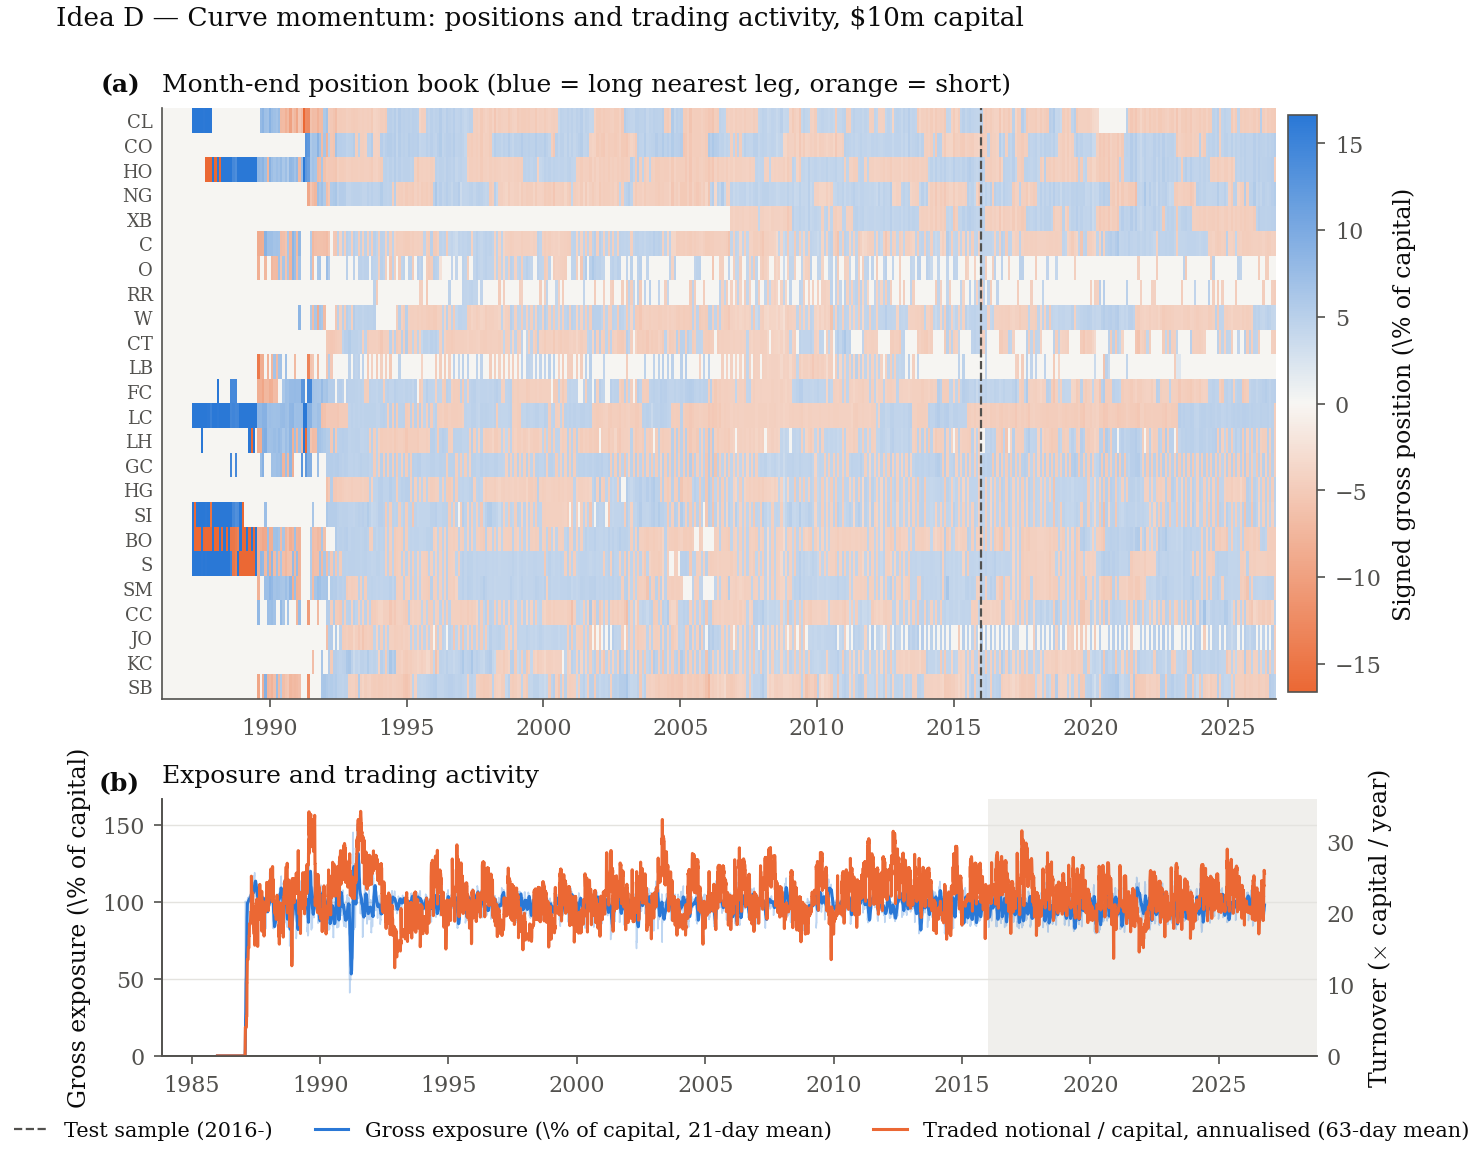

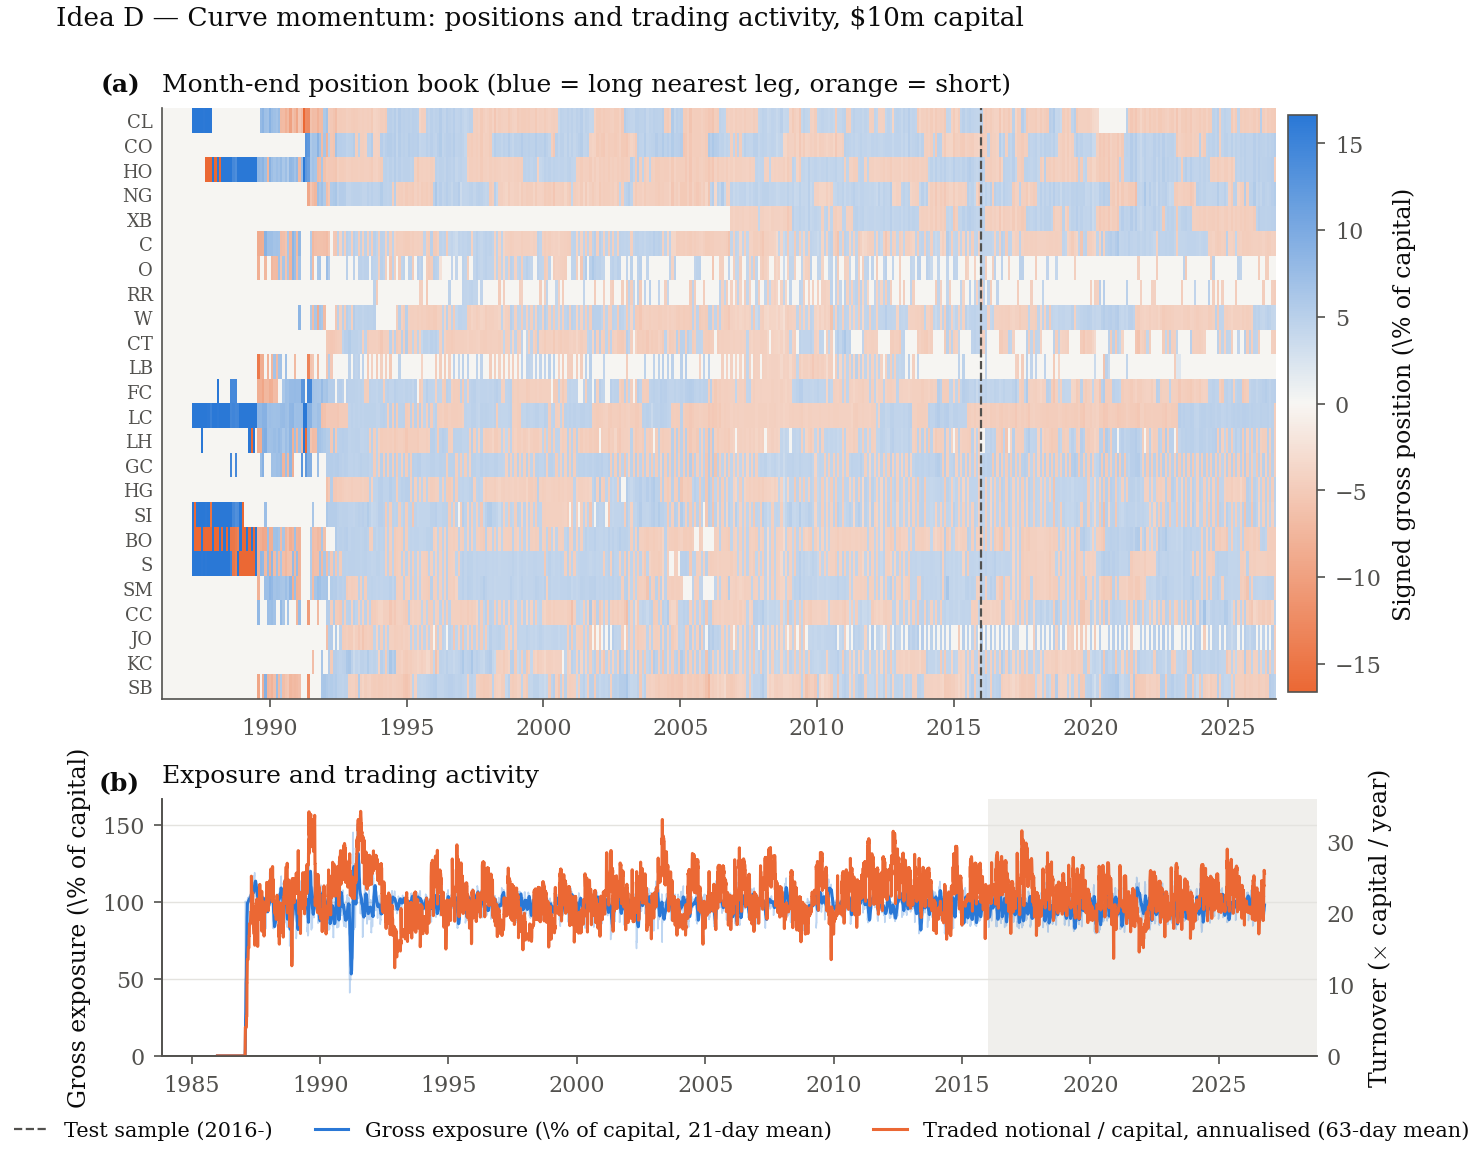

In [5]:
panel = F.position_panel(res, root_order=ROOT_ORDER)
panel.to_csv(OUT / "d_positions_month_end.csv")
fig = F.positions(res, "Idea D — Curve momentum", root_order=ROOT_ORDER)
ps.save(fig, "idea_d_positions")
display(fig)


## 7. 解读 / Reading

D 是 **documented negative/mixed** baseline：full-sample gross 很弱，
all-in net 为负；2016–2026 test 的 gross 也已经为负。D 使用 N=2 main pair、
12-month formation、month-end target、monthly rebalance；monthly engine
support 可复用，但不在 test sample 上调参。

- 当前状态与 D 的收尾：`docs/HANDOFF.md`、`docs/decisions.md` D-013。
- v1/v2 对照：`docs/v1_v2_comparison.md`。
- 旧 notebook 已 retired；恢复方式见 `docs/notebook_history.md`。
